<a href="https://colab.research.google.com/github/jfbadarom/Fisica-com-Python/blob/main/Tarefa6_Jo%C3%A3oFelipePinheiroBadar%C3%B3Moreira.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
import numpy as np
import matplotlib.pyplot as plt

In [60]:
L=2

In [61]:
def init_lattice(L):
  lattice=np.zeros([L,L])
  for i in range(L):
    for j in range(L):
        lattice[i,j]=np.random.choice([-1,1])
  return lattice

Calcular a energia para um contorno aberto(as bordas da rede não se conectam).

In [62]:
def energy(lattice):
  E=0
  l=lattice.shape[0]
  c=lattice.shape[1]

  for i in range(l):
    for j in range(c):
      E += -lattice[i,j]*(lattice[i,(j+1)%c]+lattice[i,(j-1)%c]+lattice[(i+1)%l,j]+lattice[(i-1)%l,j]) # Energia da rede para os primeiros viznhos(condição de contorno fechado, toroidal)

  return E/2
def magnetization_mod(lattice):
  M=0
  l=lattice.shape[0]
  c=lattice.shape[1]

  for i in range(l):
    for j in range(c):
      M += lattice[i,j] # Magnetização da rede

  return abs(M)


In [63]:
def MCstep(lattice, T):
  l=lattice.shape[0]
  c=lattice.shape[1]

  for k in range(c*l): # Iterando sobre C*L para dar a chance de todos os

    i,j= np.random.randint(0,l),np.random.randint(0,c)
    e_i=0
   # Cria uma matriz l+1 X c+1 com a rede no meio e com zeros na última e primeira coluna e linha.
    e_i += -lattice[i,j]*(lattice[i,(j+1)%c]+lattice[i,(j-1)%c]+lattice[(i+1)%l,j]+lattice[(i-1)%l,j]) # Energia da partícula que interagem com seus primeiros vizinhos
    delta_e= -2*e_i
    if delta_e <= 0:
        lattice[i,j] *= -1 # Inverte o spin se a variação da energia for negativa
    elif np.random.rand() < np.exp(-delta_e / T):
        lattice[i,j] *= -1 # Inverte o spin com probabilidade dada pela distribuição de Boltzmann com kB=1
  return lattice



In [64]:
def MCMH(lattice, T, N=100000):
  E=[energy(lattice)]
  M=[magnetization_mod(lattice)]
  for _ in range(N): # Montecarlo Metropolis
    lattice = MCstep(lattice, T) # Evolui a rede
    E.append(energy(lattice)) # Calula a energia da rede evoluída
    M.append(magnetization_mod(lattice)) # Calcula magnetização da rede evoluída
  return  np.array(E[N//2:]), np.array(M[N//2:]) # Descarta mestade do vetor para termalização


In [65]:
T=np.linspace(0.5,5,46)# Vetor de temperaturas


In [66]:
start=init_lattice(2) # rede inicial aleatória
C=[]
susc=[]
for t in T:
    E,M = MCMH(start,t)
    E_2= E**2
    C=np.append(C,(np.mean(E_2)-np.mean(E)**2)/(t**2*np.prod(np.shape(start)))) # Calor especcífico via montecarlo
    susc=np.append(susc,(np.mean(M**2)-np.mean(M)**2)/(t*np.prod(np.shape(start))))  # Susceptibilidade magnética via montecarlo


In [67]:
def part_func(T):
  Z=4*np.cosh(8/T)+12 # Função de partição
  return Z

In [68]:
def energy_func(T,Z):
  E=-1/Z*(32*np.sinh(8/T))# Função do valor esperado da energia
  return E

def ernergy_2_func(T,Z):
  E_2=1/Z*(256*np.cosh(8/T))# Função do valor esperado do quadrado da energia
  return E_2



In [69]:
Z = part_func(T)
E = energy_func(T,Z)
E_2 = ernergy_2_func(T,Z)
C_exact = (E_2-E**2)/T**2 # Calor especifico exato

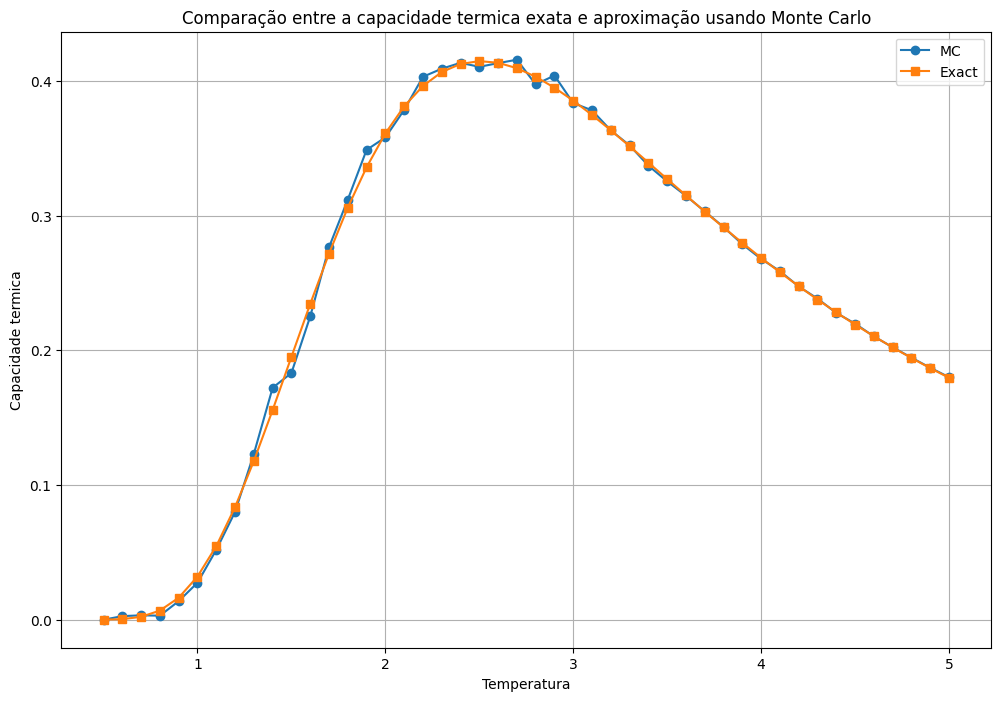

In [70]:
plt.figure(figsize=(12,8))
plt.plot(T, C, marker='o', label='MC')

plt.xlabel('Temperatura')
plt.ylabel('Capacidade termica')
plt.title('Comparação entre a capacidade termica exata e aproximação usando Monte Carlo')
plt.plot(T, C_exact/4, marker='s', label='Exact')
plt.grid()
plt.legend()

Alguma oscilação em torno do valor exato por causa do número de passos de Montecarlo dado ser baixo ainda, mas o método de montecarlo converge muito bem com o valor teórico.

In [71]:
def magnetization_mod_func(T,Z):
  MM=1/Z*(8*np.exp(8/T)+16)# Função teórica do valor esperado módulo da magnetização
  return MM
def magnetization_mod_2_func(T,Z):
  M2=1/Z*(32*np.exp(8/T)+32)# Função teórica do valor esperado magnetização ao quadrado
  return M2

In [72]:
MM = magnetization_mod_func(T,Z)
M2 = magnetization_mod_2_func(T,Z)
susc_exact = (M2-MM**2)/T # Suscepitiblidade exata

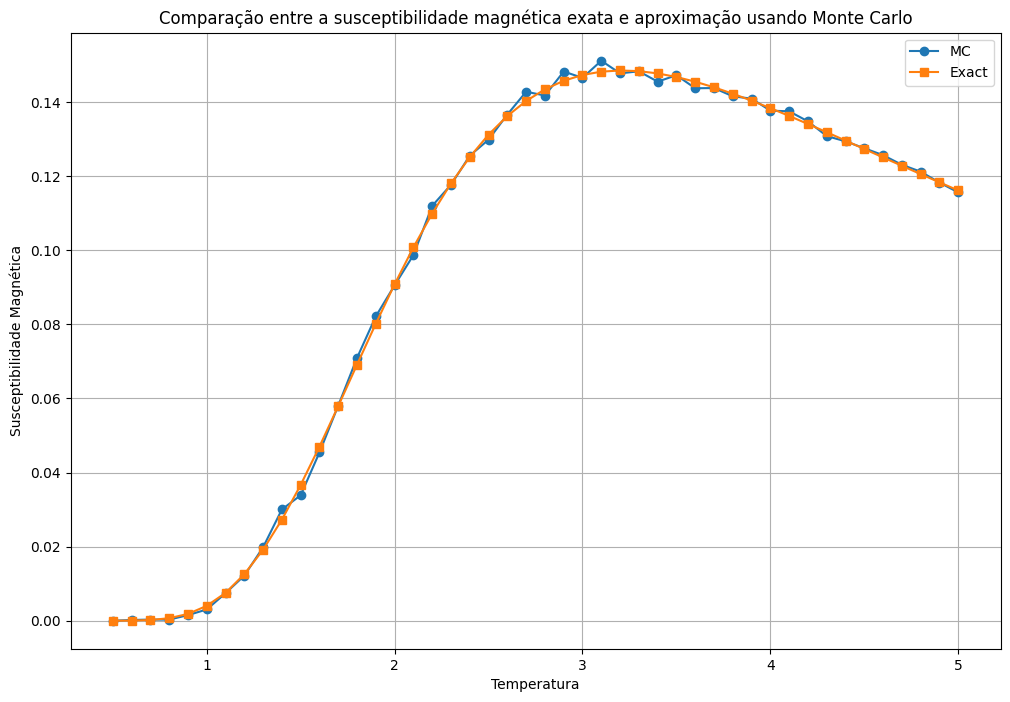

In [77]:
plt.figure(figsize=(12,8))
plt.plot(T, susc, marker='o', label='MC')

plt.xlabel('Temperatura')
plt.ylabel('Susceptibilidade Magnética')
plt.title('Comparação entre a susceptibilidade magnética exata e aproximação usando Monte Carlo')
plt.plot(T, susc_exact/4, marker='s', label='Exact')
plt.grid()
plt.legend()

Também tem alguma oscilação em torno do valor exato por causa do número de passos de Montecarlo dado ser baixo ainda, mas o método de montecarlo converge muito bem com o valor teórico.